# A-only error contributions and residual diversity

This notebook reads completed local predictions and the approved Gym training CSV. It performs **CPU-only analysis**, without fitting models, reading B outcomes, making submissions, or changing prior experiment files. Running all cells repeats the analysis and refreshes only `outputs/sequence_v004/error_analysis/`.

The six individual A models form the current candidate pool. The prior equal-three GRU ensemble is a separate reference, excluded from pair candidates. Any weight chosen here is **exploratory on A**; new v004 models and an independent confirmation step are still outstanding.

In [1]:
import os
from pathlib import Path
PROJECT = Path.cwd().resolve()
if not (PROJECT / 'data/train.csv').is_file():
    PROJECT = PROJECT / 'ventilator-pressure-prediction'
if not (PROJECT / 'data/train.csv').is_file():
    raise FileNotFoundError('Start this notebook in the PA3 project or its parent.')
OUT = PROJECT / 'outputs/sequence_v004/error_analysis'
OUT.mkdir(parents=True, exist_ok=True)
for key, subdir in [('MPLCONFIGDIR', 'matplotlib'), ('XDG_CACHE_HOME', 'xdg'), ('IPYTHONDIR', 'ipython')]:
    location = OUT / 'cache' / subdir
    location.mkdir(parents=True, exist_ok=True)
    os.environ[key] = str(location)
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import hashlib, importlib.metadata as metadata, itertools, json, platform, sys, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'svg.hashsalt': 'pa3_error_analysis_v004'})
STARTED = time.perf_counter()
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S.%fZ')
SOURCE = PROJECT / 'outputs/controlled_v003'
TRAIN_PATH = PROJECT / 'data/train.csv'
BASE_CANDIDATES = [
    'full_screen_gru_lr_0015', 'A_member_s20261103', 'A_member_s20261104',
    'full_screen_leaves_511', 'full_screen_trees_5000', 'full_incumbent',
]
REFERENCE = 'A_equal_ensemble'
PAIR_WEIGHTS = [0.0, 0.25, 0.5, 0.75, 1.0]
COUPLING_THRESHOLD = 0.90
CHUNK_ROWS = 400_000
DTYPES = {'id': 'int64', 'breath_id': 'int32', 'R': 'int8', 'C': 'int8',
          'time_step': 'float32', 'u_in': 'float32', 'u_out': 'int8', 'pressure': 'float32'}
assert REFERENCE not in BASE_CANDIDATES and len(BASE_CANDIDATES) == 6

def digest(path):
    result = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            result.update(block)
    return result.hexdigest()

def write_json(name, value):
    (OUT / name).write_text(json.dumps(value, indent=2, allow_nan=False) + '\n')

def run_event(event, **kwargs):
    with (OUT / 'analysis_run.jsonl').open('a') as stream:
        stream.write(json.dumps(dict(run_id=RUN_ID, event=event, **kwargs), allow_nan=False) + '\n')

run_event('started', scope='A-only completed-prediction analysis; CPU; no fitting')
print('CPU analysis interpreter:', sys.executable)
print('Owned output directory:', OUT)

CPU analysis interpreter: /Users/generalclasher/miniforge3/bin/python
Owned output directory: /Users/generalclasher/Documents/dsc102/pa3/ventilator-pressure-prediction/outputs/sequence_v004/error_analysis


## Verify the exact A rows and completed model scores

The CSV is read in chunks, retaining only the 6,791 A validation breaths in original row order. Every retained breath must contain 80 contiguous timesteps. All diagnostics use only `u_out == 0`, and every prediction must match the saved A row IDs and reported MAE.

In [2]:
input_paths = [TRAIN_PATH, SOURCE / 'split_breath_ids.npz', SOURCE / 'A_validation_row_ids.npy']
for trial in BASE_CANDIDATES + [REFERENCE]:
    input_paths.extend([SOURCE / f'{trial}.json', SOURCE / f'{trial}_validation_predictions.npy'])
input_stats_before = {str(p.relative_to(PROJECT)): (p.stat().st_size, p.stat().st_mtime_ns) for p in input_paths}
input_hashes = {str(p.relative_to(PROJECT)): digest(p) for p in input_paths}
with np.load(SOURCE / 'split_breath_ids.npz', allow_pickle=False) as archive:
    # Deliberately read only A keys; B arrays/outcomes are not used.
    a_breath_ids = archive['A_validation'].copy()
    a_fit_ids = archive['A_fit'].copy()
assert len(a_breath_ids) == 6791 and len(np.unique(a_breath_ids)) == 6791
assert not np.intersect1d(a_breath_ids, a_fit_ids).size
kept = []
for chunk in pd.read_csv(TRAIN_PATH, usecols=list(DTYPES), dtype=DTYPES, chunksize=CHUNK_ROWS):
    part = chunk.loc[chunk.breath_id.isin(a_breath_ids)]
    if len(part):
        kept.append(part.copy())
frame = pd.concat(kept, ignore_index=True)
del kept, chunk, part
assert len(frame) == len(a_breath_ids) * 80
blocks = frame.breath_id.to_numpy().reshape(-1, 80)
group_ids = blocks[:, 0]
assert np.all(blocks == group_ids[:, None])
assert np.array_equal(np.sort(group_ids), np.sort(a_breath_ids))
assert len(np.unique(group_ids)) == 6791
assert frame.id.is_unique and np.all(np.diff(frame.id.to_numpy()) > 0)
assert np.all(np.diff(frame.time_step.to_numpy().reshape(-1, 80), axis=1) > 0)
assert np.isin(frame.u_out.to_numpy(), [0, 1]).all()
for col in ['R', 'C']:
    values = frame[col].to_numpy().reshape(-1, 80)
    assert np.all(values == values[:, :1])
scored = frame.u_out.to_numpy() == 0
scored_rows = frame.loc[scored].copy().reset_index(drop=True)
saved_ids = np.load(SOURCE / 'A_validation_row_ids.npy', allow_pickle=False)
assert np.array_equal(scored_rows.id.to_numpy(), saved_ids)
assert len(scored_rows) == 206098
scored_rows['absolute_step'] = np.tile(np.arange(80), len(group_ids))[scored]
rank = scored_rows.groupby('breath_id', sort=False).cumcount().to_numpy()
inspiration_count = scored_rows.groupby('breath_id', sort=False).id.transform('size').to_numpy()
scored_rows['inspiration_relative_position'] = rank / np.maximum(inspiration_count - 1, 1)
r = scored_rows.inspiration_relative_position.to_numpy()
scored_rows['inspiration_phase'] = np.select([r < 1/3, r < 2/3], ['early', 'middle'], default='late')
y = scored_rows.pressure.to_numpy(dtype=np.float64)
assert np.isfinite(y).all()
records, predictions, individual_rows = {}, {}, []
for trial in BASE_CANDIDATES + [REFERENCE]:
    record = json.loads((SOURCE / f'{trial}.json').read_text())
    assert record['split'] == 'A'
    if trial in BASE_CANDIDATES:
        assert record['status'] == 'complete' and record['record_type'] == 'trial'
    prediction = np.load(SOURCE / f'{trial}_validation_predictions.npy', allow_pickle=False)
    assert prediction.shape == y.shape and np.isfinite(prediction).all()
    prediction = prediction.astype(np.float64, copy=False)
    observed = float(np.abs(prediction - y).mean())
    assert np.isclose(observed, record['validation_mae'], rtol=1e-10, atol=1e-10), trial
    records[trial], predictions[trial] = record, prediction
    individual_rows.append(dict(trial=trial,
        family=record.get('definition', {}).get('family', 'GRU ensemble'),
        role='individual candidate' if trial in BASE_CANDIDATES else 'separate reference',
        seed=record.get('seed'), mae=observed, reported_mae=float(record['validation_mae']),
        scored_rows=len(y)))
identities = [records[t]['identity'] for t in BASE_CANDIDATES]
assert len({item['val_breath_sha256'] for item in identities}) == 1
assert len({item['fit_breath_sha256'] for item in identities}) == 1
scores = pd.DataFrame(individual_rows).sort_values('mae').reset_index(drop=True)
scores.to_csv(OUT / 'candidate_scores.csv', index=False)
best_gru = scores[(scores.family == 'GRU') & (scores.role == 'individual candidate')].iloc[0].trial
best_tree = scores[(scores.family == 'LightGBM') & (scores.role == 'individual candidate')].iloc[0].trial
best_individual = scores[scores.role == 'individual candidate'].iloc[0]
residuals = pd.DataFrame({t: predictions[t] - y for t in BASE_CANDIDATES})
best_error = np.abs(residuals[best_gru].to_numpy())
GLOBAL_TAE = float(best_error.sum(dtype=np.float64))
print(f'Verified {len(group_ids):,} A breaths and {len(y):,} scored row IDs; every MAE matches metadata.')
print('Best GRU:', best_gru, '| Best tree:', best_tree)
display(scores)

Verified 6,791 A breaths and 206,098 scored row IDs; every MAE matches metadata.
Best GRU: full_screen_gru_lr_0015 | Best tree: full_screen_leaves_511


,trial,family,role,seed,mae,reported_mae,scored_rows
0,full_screen_gru_lr_0015,GRU,individual candidate,20261102.0,0.496273,0.496273,206098
1,A_equal_ensemble,GRU ensemble,separate reference,NaN,0.505135,0.505135,206098
2,A_member_s20261103,GRU,individual candidate,20261103.0,0.509418,0.509418,206098
3,A_member_s20261104,GRU,individual candidate,20261104.0,0.580901,0.580901,206098
4,full_screen_leaves_511,LightGBM,individual candidate,20261102.0,0.618996,0.618996,206098
5,full_screen_trees_5000,LightGBM,individual candidate,20261102.0,0.625763,0.625763,206098
6,full_incumbent,LightGBM,individual candidate,20261102.0,0.664386,0.664386,206098


## Error contribution before error rate

For each partition, **total absolute error (TAE)** is the sum of scored absolute errors; its share of global TAE accounts for both subgroup size and difficulty. MAE is TAE divided by the number of scored rows. Signed bias is prediction minus actual pressure. All partition TAEs below must sum to the same global total.

Relative inspiration position is the rank among scored points divided by the final scored rank. Early is `< 1/3`, middle is `[1/3, 2/3)`, and late is `>= 2/3`. These are descriptive slices, not causal explanations.

In [3]:
partitions = {'R': ['R'], 'C': ['C'], 'R_C': ['R', 'C'],
              'absolute_step': ['absolute_step'], 'inspiration_phase': ['inspiration_phase'],
              'R_C_phase': ['R', 'C', 'inspiration_phase']}
partition_checks = {}
tables = {}

def summarize(keys):
    source = scored_rows[keys + ['breath_id']].copy()
    source['absolute_error'] = best_error
    source['signed_error'] = residuals[best_gru].to_numpy()
    result = source.groupby(keys, observed=True, sort=True).agg(
        scored_rows=('absolute_error', 'size'), breaths=('breath_id', 'nunique'),
        total_absolute_error=('absolute_error', 'sum'), signed_error_sum=('signed_error', 'sum')).reset_index()
    result['mae'] = result.total_absolute_error / result.scored_rows
    result['bias_pred_minus_true'] = result.signed_error_sum / result.scored_rows
    result['share_global_error'] = result.total_absolute_error / GLOBAL_TAE
    result['share_scored_rows'] = result.scored_rows / len(y)
    result = result.drop(columns='signed_error_sum')
    assert int(result.scored_rows.sum()) == len(y)
    assert np.isclose(result.total_absolute_error.sum(), GLOBAL_TAE, rtol=1e-12, atol=1e-8)
    assert np.isclose(result.share_global_error.sum(), 1.0, rtol=1e-12, atol=1e-12)
    return result.sort_values('total_absolute_error', ascending=False).reset_index(drop=True)

for label, keys in partitions.items():
    table = summarize(keys)
    tables[label] = table
    table.to_csv(OUT / f'by_{label}.csv', index=False)
    partition_checks[label] = dict(scored_rows=int(table.scored_rows.sum()),
                                   total_absolute_error=float(table.total_absolute_error.sum()),
                                   sums_match_global=True)
    display(Markdown(f'**{label}: ranked by total absolute error**'))
    display(table.head(12))
print(f'Global GRU TAE: {GLOBAL_TAE:,.4f}; MAE: {GLOBAL_TAE / len(y):.8f}')

Global GRU TAE: 102,280.7760; MAE: 0.49627253


**R: ranked by total absolute error**

,R,scored_rows,breaths,total_absolute_error,mae,bias_pred_minus_true,share_global_error,share_scored_rows
0,50,83320,2709,54816.874862,0.657908,0.032739,0.535945,0.404274
1,5,67592,2239,24597.294975,0.363908,-0.006798,0.240488,0.327960
2,20,55186,1843,22866.606170,0.414355,0.006400,0.223567,0.267766


**C: ranked by total absolute error**

,C,scored_rows,breaths,total_absolute_error,mae,bias_pred_minus_true,share_global_error,share_scored_rows
0,10,76494,2522,43083.626065,0.563229,0.045673,0.421229,0.371154
1,50,66693,2218,29723.785341,0.445681,-0.017821,0.290610,0.323598
2,20,62911,2051,29473.364601,0.468493,0.005030,0.288161,0.305248


**R_C: ranked by total absolute error**

... (3 outputs left out)

**inspiration_phase: ranked by total absolute error**

,inspiration_phase,scored_rows,breaths,total_absolute_error,mae,bias_pred_minus_true,share_global_error,share_scored_rows
0,late,70938,6791,37808.553740,0.532980,-0.015437,0.369655,0.344195
1,middle,65782,6791,34373.171081,0.522532,-0.002895,0.336067,0.319178
2,early,69378,6791,30099.051187,0.433841,0.056315,0.294279,0.336626


**R_C_phase: ranked by total absolute error**

,R,C,inspiration_phase,scored_rows,breaths,total_absolute_error,mae,bias_pred_minus_true,share_global_error,share_scored_rows
0,50,10,late,12802,1226,8748.981851,0.683407,0.011988,0.085539,0.062116
1,50,10,early,12664,1226,8174.385370,0.645482,0.147276,0.079921,0.061446
2,50,10,middle,11978,1226,7855.863014,0.655858,0.016313,0.076807,0.058118
3,50,50,late,7914,737,5870.172037,0.741745,-0.004483,0.057393,0.038399
4,50,50,middle,7187,737,5732.042409,0.797557,-0.028366,0.056042,0.034872
5,50,20,late,8016,746,5364.110607,0.669175,0.011960,0.052445,0.038894
6,50,20,middle,7275,746,5346.946208,0.734975,0.047543,0.052277,0.035299
7,5,10,late,7663,749,4197.404798,0.547750,-0.016683,0.041038,0.037181
8,50,20,early,7846,746,3996.603590,0.509381,0.030165,0.039075,0.038069
9,50,50,early,7638,737,3727.769778,0.488056,0.009795,0.036446,0.037060


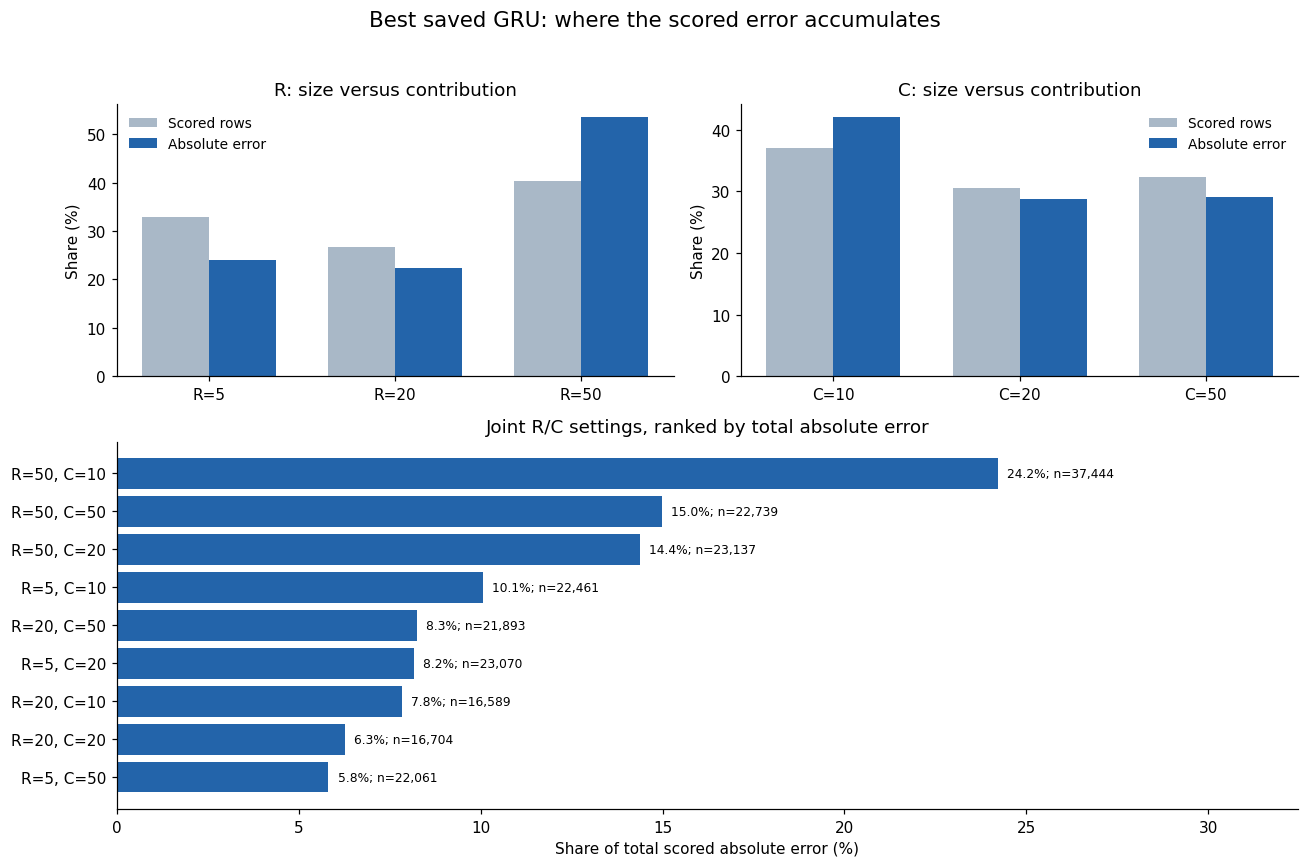

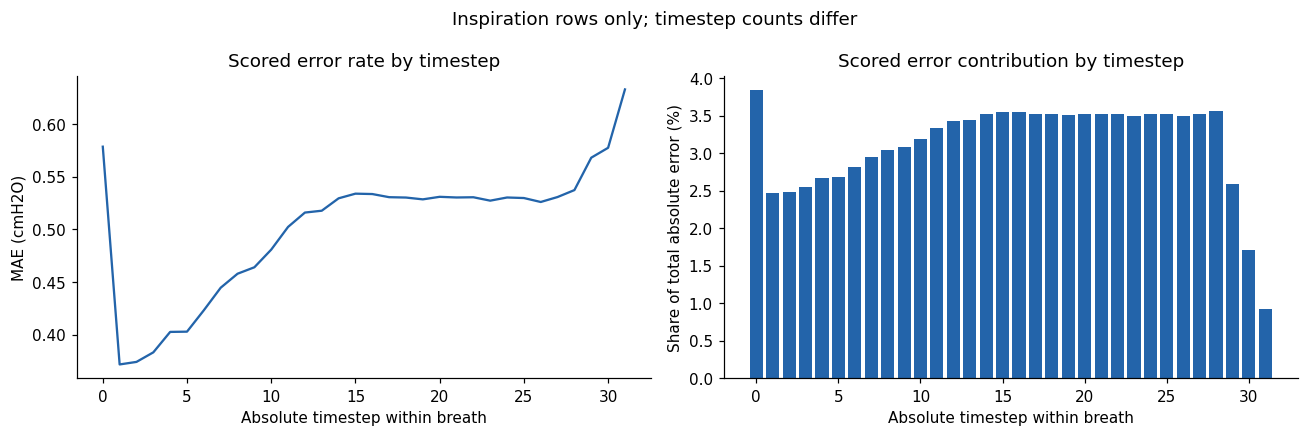

In [4]:
FIGURES = []
def save_figure(fig, name):
    for suffix in ['png', 'svg']:
        path = OUT / f'{name}.{suffix}'
        fig.savefig(path, bbox_inches='tight', metadata={'Date': None} if suffix == 'svg' else None)
        FIGURES.append(path)
    display(fig)
    plt.close(fig)

fig = plt.figure(figsize=(12, 8))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.35])
for key, ax in [('R', fig.add_subplot(grid[0, 0])), ('C', fig.add_subplot(grid[0, 1]))]:
    table = tables[key].sort_values(key)
    x = np.arange(len(table))
    ax.bar(x - .18, table.share_scored_rows * 100, .36, label='Scored rows', color='#a9b8c7')
    ax.bar(x + .18, table.share_global_error * 100, .36, label='Absolute error', color='#2364aa')
    ax.set_xticks(x, [f'{key}={v}' for v in table[key]])
    ax.set_ylabel('Share (%)')
    ax.set_title(f'{key}: size versus contribution')
    ax.legend(frameon=False, fontsize=9)
ax = fig.add_subplot(grid[1, :])
table = tables['R_C'].iloc[::-1]
labels = [f'R={int(row.R)}, C={int(row.C)}' for row in table.itertuples()]
ax.barh(labels, table.share_global_error * 100, color='#2364aa')
for i, row in enumerate(table.itertuples()):
    ax.text(row.share_global_error * 100 + .25, i,
            f'{row.share_global_error:.1%}; n={row.scored_rows:,}', va='center', fontsize=8)
ax.set_xlim(0, float(table.share_global_error.max() * 100) * 1.34)
ax.set_xlabel('Share of total scored absolute error (%)')
ax.set_title('Joint R/C settings, ranked by total absolute error')
fig.suptitle('Best saved GRU: where the scored error accumulates', fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .96))
save_figure(fig, 'r_c_error_contributions')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
step_table = tables['absolute_step'].sort_values('absolute_step')
axes[0].plot(step_table.absolute_step, step_table.mae, color='#2364aa')
axes[0].set(xlabel='Absolute timestep within breath', ylabel='MAE (cmH2O)', title='Scored error rate by timestep')
axes[1].bar(step_table.absolute_step, step_table.share_global_error * 100, color='#2364aa')
axes[1].set(xlabel='Absolute timestep within breath', ylabel='Share of total absolute error (%)', title='Scored error contribution by timestep')
fig.suptitle('Inspiration rows only; timestep counts differ')
fig.tight_layout()
save_figure(fig, 'absolute_step_error_profile')

## Selected hard cases

The following six breaths have the greatest **total absolute error for the best saved GRU**. They are selected hard cases, **not a representative sample**. Curves show actual pressure, this GRU, and the best saved tree only during inspiration; expiration contributes no plotted metric or curve.

,breath_id,R,C,scored_rows,total_absolute_error,tree_total_absolute_error,mae,tree_mae,share_global_error
0,59872,50,10,32,148.818976,88.858423,4.650593,2.776826,0.001455
1,65844,50,10,32,137.720727,89.586420,4.303773,2.799576,0.001346
2,18594,50,10,32,131.080493,92.037351,4.096265,2.876167,0.001282
3,5758,50,10,32,117.687717,150.311180,3.677741,4.697224,0.001151
4,114598,50,10,32,114.445388,111.245514,3.576418,3.476422,0.001119
5,82930,50,10,32,113.180178,43.503836,3.536881,1.359495,0.001107


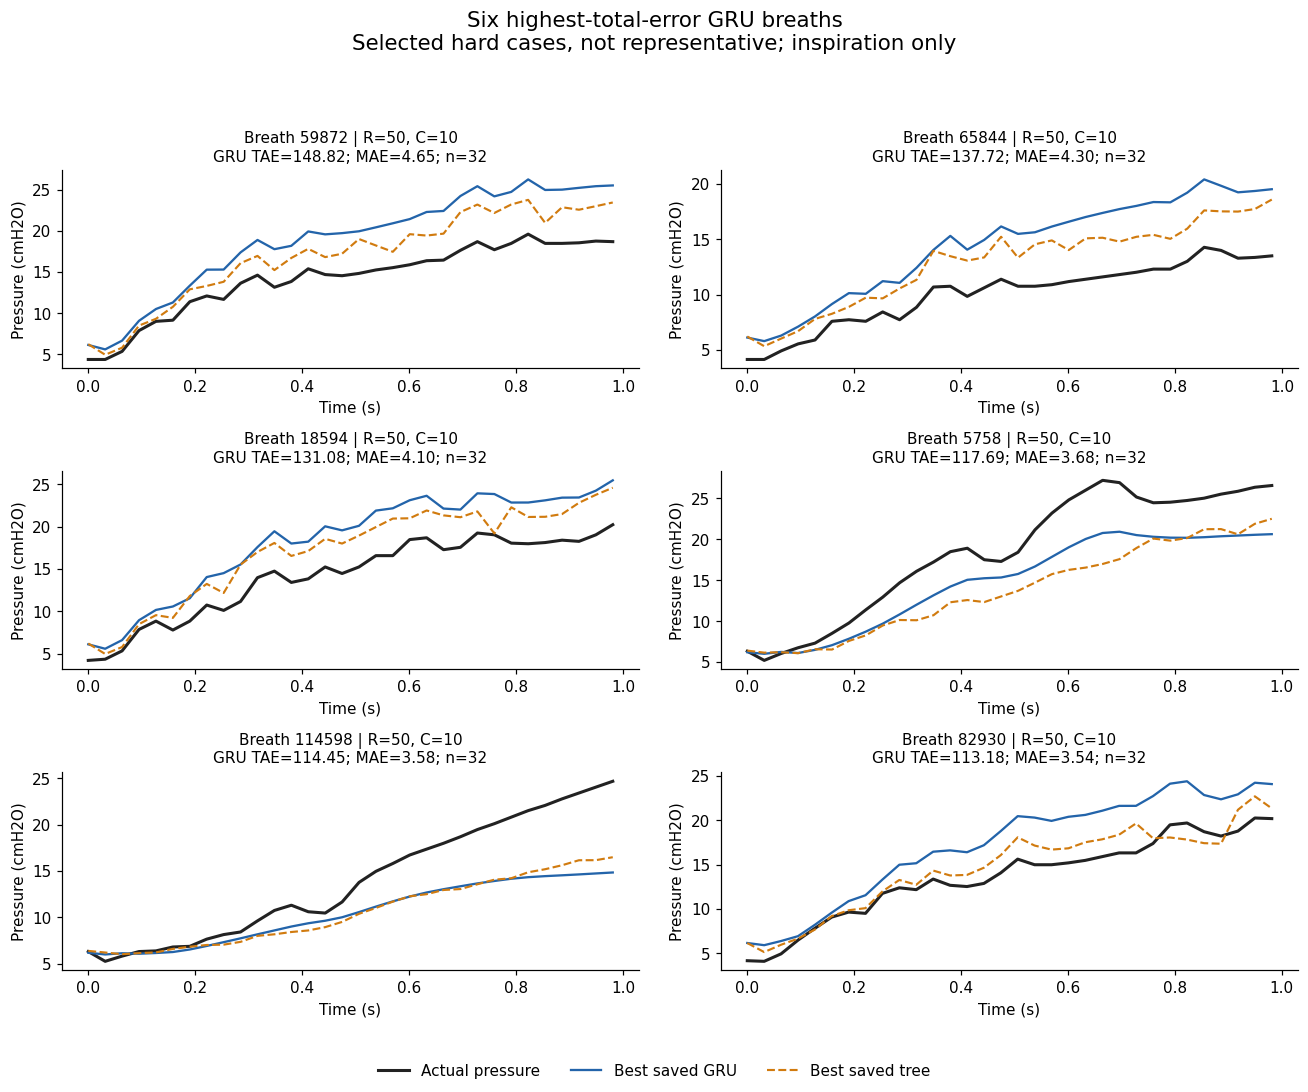

In [5]:
case_data = scored_rows[['breath_id', 'R', 'C']].copy()
case_data['absolute_error'] = best_error
case_data['tree_absolute_error'] = np.abs(predictions[best_tree] - y)
case_table = case_data.groupby('breath_id', sort=False).agg(
    R=('R', 'first'), C=('C', 'first'), scored_rows=('absolute_error', 'size'),
    total_absolute_error=('absolute_error', 'sum'), tree_total_absolute_error=('tree_absolute_error', 'sum')).reset_index()
case_table['mae'] = case_table.total_absolute_error / case_table.scored_rows
case_table['tree_mae'] = case_table.tree_total_absolute_error / case_table.scored_rows
case_table['share_global_error'] = case_table.total_absolute_error / GLOBAL_TAE
assert np.isclose(case_table.total_absolute_error.sum(), GLOBAL_TAE, rtol=1e-12, atol=1e-8)
case_table = case_table.sort_values('total_absolute_error', ascending=False).reset_index(drop=True)
case_table.to_csv(OUT / 'per_breath_error.csv', index=False)
hardest = case_table.head(6).copy()
hardest.to_csv(OUT / 'six_selected_hard_cases.csv', index=False)
display(hardest)
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, row in zip(axes.flat, hardest.itertuples()):
    mask = scored_rows.breath_id.to_numpy() == row.breath_id
    times = scored_rows.loc[mask, 'time_step'].to_numpy()
    ax.plot(times, y[mask], color='#222222', lw=2, label='Actual pressure')
    ax.plot(times, predictions[best_gru][mask], color='#2364aa', lw=1.5, label='Best saved GRU')
    ax.plot(times, predictions[best_tree][mask], color='#d17b0f', lw=1.4, ls='--', label='Best saved tree')
    ax.set_title(f'Breath {row.breath_id} | R={row.R}, C={row.C}\nGRU TAE={row.total_absolute_error:.2f}; MAE={row.mae:.2f}; n={row.scored_rows}', fontsize=10)
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Pressure (cmH2O)')
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
fig.suptitle('Six highest-total-error GRU breaths\nSelected hard cases, not representative; inspiration only', fontsize=14)
fig.tight_layout(rect=(0, .05, 1, .94))
save_figure(fig, 'six_selected_hard_case_breaths')

## Signed residual diversity and pair weights on A

Correlations use signed residuals `(prediction - true pressure)` on the same A rows. Closely correlated errors can limit averaging gains. Every unordered pair of the six **individual** models is evaluated at weights `0, .25, .5, .75, 1` for its first model. Endpoints are the individual models; `.5` is the pair mean. No model is retrained, and no B outcomes are read.

The best weight per pair and the ranking below are descriptive A selections. Repeated A comparisons can overstate expected gains; these weights must not be presented as independently confirmed or as the final v004 selection.

In [6]:
corr = residuals.corr(method='pearson')
assert np.isfinite(corr.to_numpy()).all()
assert np.allclose(corr.to_numpy(), corr.to_numpy().T) and np.allclose(np.diag(corr), 1)
corr.to_csv(OUT / 'signed_residual_correlations.csv')
pair_records = []
for left, right in itertools.combinations(BASE_CANDIDATES, 2):
    ra = residuals[left].to_numpy(); rb = residuals[right].to_numpy()
    endpoint_mae_a = float(np.abs(ra).mean()); endpoint_mae_b = float(np.abs(rb).mean())
    for weight in PAIR_WEIGHTS:
        blended = weight * ra + (1 - weight) * rb
        mae = float(np.abs(blended).mean())
        pair_records.append(dict(model_a=left, model_b=right, weight_a=weight, weight_b=1-weight,
            kind='endpoint' if weight in [0.0, 1.0] else 'pair blend', mae=mae,
            bias_pred_minus_true=float(blended.mean()), residual_correlation=float(corr.loc[left, right]),
            endpoint_a_mae=endpoint_mae_a, endpoint_b_mae=endpoint_mae_b,
            gain_vs_better_endpoint=min(endpoint_mae_a, endpoint_mae_b)-mae,
            gain_vs_global_best_individual=float(best_individual.mae)-mae,
            same_signed_error_fraction=float(np.mean(np.sign(ra) == np.sign(rb)))))
pair_grid = pd.DataFrame(pair_records).sort_values(['mae', 'model_a', 'model_b', 'weight_a']).reset_index(drop=True)
assert len(pair_grid) == 75
pair_blends = pair_grid[pair_grid.kind == 'pair blend'].copy().reset_index(drop=True)
assert len(pair_blends) == 45
best_pairs = pair_grid.drop_duplicates(['model_a', 'model_b']).reset_index(drop=True)
assert len(best_pairs) == 15
pair_means = pair_grid[pair_grid.weight_a == .5].copy().reset_index(drop=True)
pair_grid.to_csv(OUT / 'pair_weight_grid_with_endpoints.csv', index=False)
pair_blends.to_csv(OUT / 'ranked_pair_blends.csv', index=False)
best_pairs.to_csv(OUT / 'selected_weights_per_pair.csv', index=False)
pair_means.to_csv(OUT / 'equal_weight_pair_means.csv', index=False)

# Threshold-based connected groups describe coupling, not independent statistical clusters.
unseen = set(BASE_CANDIDATES)
coupled_groups = []
while unseen:
    seed = min(unseen); component = {seed}; frontier = [seed]; unseen.remove(seed)
    while frontier:
        current = frontier.pop()
        linked = {t for t in unseen if corr.loc[current, t] >= COUPLING_THRESHOLD}
        component.update(linked); frontier.extend(sorted(linked)); unseen.difference_update(linked)
    coupled_groups.append(sorted(component))
coupling = dict(threshold=COUPLING_THRESHOLD, rule='Connected components of Pearson signed-residual correlation >= threshold; descriptive only', groups=coupled_groups)
write_json('descriptive_coupled_groups.json', coupling)
display(Markdown('**Signed residual correlations**'))
display(corr.style.format('{:.3f}').background_gradient(cmap='Blues', vmin=0, vmax=1))
display(Markdown('**Best A-only weights per unordered pair, including individual endpoints**'))
display(best_pairs.head(10))
print('Descriptive coupled groups:', coupled_groups)

Descriptive coupled groups: [['A_member_s20261103', 'full_screen_gru_lr_0015'], ['A_member_s20261104'], ['full_incumbent', 'full_screen_leaves_511', 'full_screen_trees_5000']]


**Signed residual correlations**

,full_screen_gru_lr_0015,A_member_s20261103,A_member_s20261104,full_screen_leaves_511,full_screen_trees_5000,full_incumbent
full_screen_gru_lr_0015,1.000,0.914,0.848,0.580,0.580,0.568
A_member_s20261103,0.914,1.000,0.872,0.596,0.596,0.585
A_member_s20261104,0.848,0.872,1.000,0.615,0.617,0.613
full_screen_leaves_511,0.580,0.596,0.615,1.000,0.965,0.960
full_screen_trees_5000,0.580,0.596,0.617,0.965,1.000,0.994
full_incumbent,0.568,0.585,0.613,0.960,0.994,1.000


**Best A-only weights per unordered pair, including individual endpoints**

,model_a,model_b,weight_a,weight_b,kind,mae,bias_pred_minus_true,residual_correlation,endpoint_a_mae,endpoint_b_mae,gain_vs_better_endpoint,gain_vs_global_best_individual,same_signed_error_fraction
0,full_screen_gru_lr_0015,full_screen_leaves_511,0.75,0.25,pair blend,0.485082,0.010257,0.580483,0.496273,0.618996,0.011190,0.011190,0.713049
1,full_screen_gru_lr_0015,full_screen_trees_5000,0.75,0.25,pair blend,0.486267,0.010474,0.580418,0.496273,0.625763,0.010005,0.010005,0.712569
2,full_screen_gru_lr_0015,A_member_s20261103,0.50,0.50,pair blend,0.489649,0.013757,0.914443,0.496273,0.509418,0.006624,0.006624,0.846452
3,full_screen_gru_lr_0015,full_incumbent,0.75,0.25,pair blend,0.492816,0.010581,0.568313,0.496273,0.664386,0.003457,0.003457,0.712971
4,full_screen_gru_lr_0015,A_member_s20261104,1.00,0.00,endpoint,0.496273,0.012720,0.848284,0.496273,0.580901,0.000000,0.000000,0.821449
5,A_member_s20261103,full_screen_leaves_511,0.75,0.25,pair blend,0.497056,0.011812,0.596288,0.509418,0.618996,0.012362,-0.000784,0.718110
6,A_member_s20261103,full_screen_trees_5000,0.75,0.25,pair blend,0.498347,0.012030,0.595631,0.509418,0.625763,0.011071,-0.002075,0.717819
7,A_member_s20261103,full_incumbent,0.75,0.25,pair blend,0.505163,0.012137,0.585281,0.509418,0.664386,0.004255,-0.008891,0.719498
8,A_member_s20261103,A_member_s20261104,1.00,0.00,endpoint,0.509418,0.014794,0.871746,0.509418,0.580901,0.000000,-0.013146,0.834457
9,A_member_s20261104,full_screen_leaves_511,0.50,0.50,pair blend,0.550573,0.006980,0.615068,0.580901,0.618996,0.030327,-0.054301,0.722952


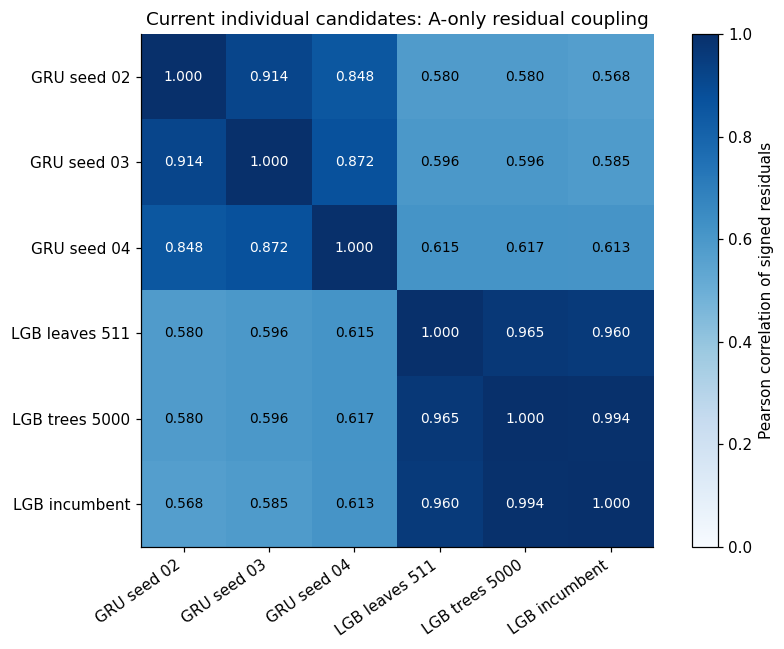

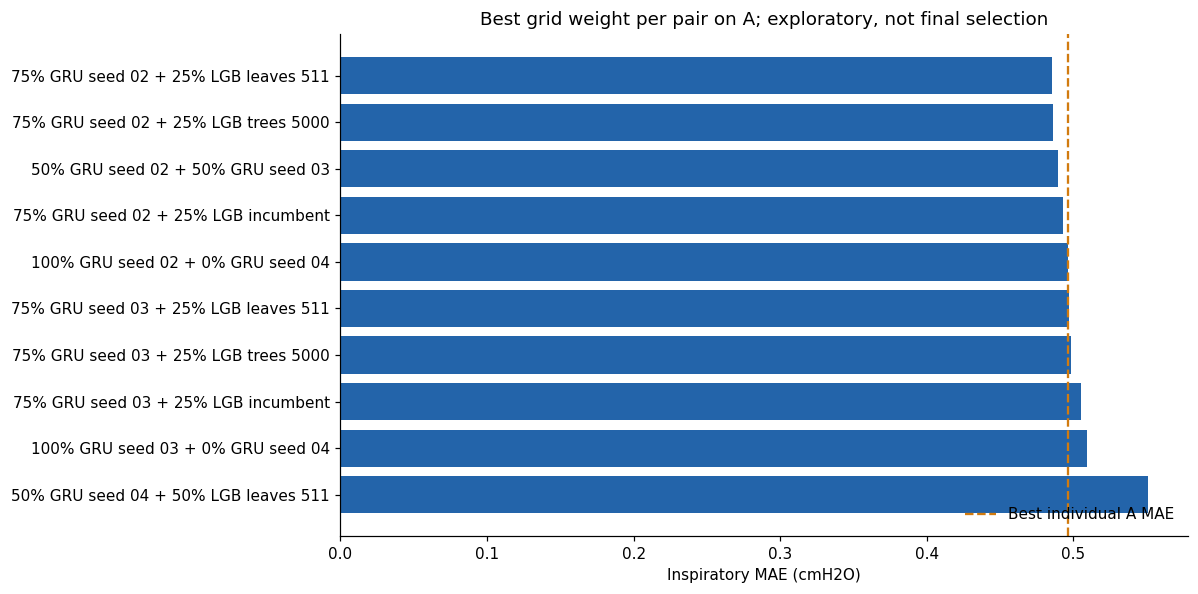

In [7]:
SHORT = {'full_screen_gru_lr_0015': 'GRU seed 02', 'A_member_s20261103': 'GRU seed 03',
         'A_member_s20261104': 'GRU seed 04', 'full_screen_leaves_511': 'LGB leaves 511',
         'full_screen_trees_5000': 'LGB trees 5000', 'full_incumbent': 'LGB incumbent'}
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr.to_numpy(), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(6), [SHORT[t] for t in BASE_CANDIDATES], rotation=35, ha='right')
ax.set_yticks(range(6), [SHORT[t] for t in BASE_CANDIDATES])
for i in range(6):
    for j in range(6):
        value = corr.iloc[i, j]
        ax.text(j, i, f'{value:.3f}', ha='center', va='center', color='white' if value > .8 else 'black', fontsize=9)
fig.colorbar(image, ax=ax, label='Pearson correlation of signed residuals', fraction=.045)
ax.set_title('Current individual candidates: A-only residual coupling')
fig.tight_layout()
save_figure(fig, 'signed_residual_correlation_heatmap')

plot_pairs = best_pairs.head(10).iloc[::-1]
labels = [f'{row.weight_a:.0%} {SHORT[row.model_a]} + {row.weight_b:.0%} {SHORT[row.model_b]}' for row in plot_pairs.itertuples()]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(labels, plot_pairs.mae, color='#2364aa')
ax.axvline(float(best_individual.mae), color='#d17b0f', ls='--', label='Best individual A MAE')
ax.set(xlabel='Inspiratory MAE (cmH2O)', title='Best grid weight per pair on A; exploratory, not final selection')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()
save_figure(fig, 'exploratory_pair_mae')

## Findings and reproducibility record

Subgroup priorities use TAE, rather than selecting only the largest MAE. Hard-case plots are deliberately selected examples. Correlation and pair-weight results describe the current A candidate pool; they do not establish causation, label noise, outlier-removal rules, or a final ensemble. No cleaning, clipping, imputation, scaling fit, model inference, or training occurs in this notebook.

In [8]:
best_pair = best_pairs.iloc[0].to_dict()
upper = [(left, right, float(corr.loc[left, right])) for left, right in itertools.combinations(BASE_CANDIDATES, 2)]
least = min(upper, key=lambda item: item[2]); most = max(upper, key=lambda item: item[2])
unchanged = all((p.stat().st_size, p.stat().st_mtime_ns) == input_stats_before[str(p.relative_to(PROJECT))] for p in input_paths)
assert unchanged
summary = dict(
    run_id=RUN_ID, created_at_utc=datetime.now(timezone.utc).isoformat(),
    scope='Exploratory A-only CPU residual analysis; no fitting, inference, B outcomes, or final selection',
    interpreter=sys.executable, platform=platform.platform(),
    versions={name: metadata.version(name) for name in ['numpy', 'pandas', 'matplotlib', 'nbformat', 'nbclient']},
    runtime_seconds=time.perf_counter()-STARTED,
    input_hashes=input_hashes, input_sizes_and_mtimes_unchanged=unchanged,
    configs=dict(base_candidates=BASE_CANDIDATES, excluded_reference_from_pair_candidates=REFERENCE,
                 pair_weights_a=PAIR_WEIGHTS, chunk_rows=CHUNK_ROWS, dtypes=DTYPES,
                 coupling_threshold=COUPLING_THRESHOLD,
                 relative_inspiration_definition='Rank among u_out==0 rows divided by count-1; thirds at 1/3 and 2/3'),
    candidate_configs={t: dict(definition=records[t].get('definition'), seed=records[t].get('seed'),
                               validation_mae=records[t]['validation_mae'], identity_sha256=records[t].get('identity_sha256'))
                       for t in BASE_CANDIDATES},
    validation_breaths=len(group_ids), scored_rows=len(y), row_ids_exact_match=True,
    all_metadata_maes_match=True, A_fit_validation_disjoint=True, B_outcomes_used=False,
    best_saved_gru=best_gru, best_saved_tree=best_tree,
    best_gru_mae=GLOBAL_TAE/len(y), best_gru_total_absolute_error=GLOBAL_TAE,
    partition_sum_checks=partition_checks,
    top_error_contributions={key: table.head(6).to_dict(orient='records') for key, table in tables.items()},
    selected_hard_breaths=hardest.to_dict(orient='records'),
    current_A_best_pair=best_pair,
    pair_improvement_vs_best_individual_percent=100 * (float(best_individual.mae)-best_pair['mae']) / float(best_individual.mae),
    least_correlated_pair=dict(model_a=least[0], model_b=least[1], correlation=least[2]),
    most_correlated_pair=dict(model_a=most[0], model_b=most[1], correlation=most[2]),
    descriptive_coupling=coupling,
    equal_three_reference_mae=float(scores[scores.trial == REFERENCE].iloc[0].mae),
    current_pool_status='New v004 models may join later. A-selected weights are not final or independently confirmed.',
    figures=[str(path.relative_to(PROJECT)) for path in FIGURES],
    figure_sha256={str(path.relative_to(PROJECT)): digest(path) for path in FIGURES},
)
write_json('summary.json', summary)
run_event('completed', runtime_seconds=summary['runtime_seconds'], scored_rows=len(y),
          best_gru_mae=summary['best_gru_mae'], exploratory_pair_mae=best_pair['mae'], inputs_unchanged=True)
for key in ['R', 'C', 'R_C', 'inspiration_phase']:
    leader = tables[key].iloc[0]
    description = ', '.join(f'{col}={leader[col]}' for col in partitions[key])
    display(Markdown(f'- **Largest {key} contribution:** {description}; '
        f'{leader.share_global_error:.2%} of total error from {leader.share_scored_rows:.2%} of scored rows; '
        f'MAE {leader.mae:.5f}.'))
display(Markdown(f'**Exploratory best pair on A:** {best_pair["weight_a"]:.0%} {best_pair["model_a"]} + '
    f'{best_pair["weight_b"]:.0%} {best_pair["model_b"]}; MAE **{best_pair["mae"]:.8f}**, '
    f'{summary["pair_improvement_vs_best_individual_percent"]:.2f}% below the best individual. '
    'This is a current-pool A finding, not a final selection.'))
print(f'Completed in {summary["runtime_seconds"]:.2f} seconds. Tables, PNG/SVG figures, hashes, configuration and run log: {OUT}')

Completed in 3.60 seconds. Tables, PNG/SVG figures, hashes, configuration and run log: /Users/generalclasher/Documents/dsc102/pa3/ventilator-pressure-prediction/outputs/sequence_v004/error_analysis


- **Largest R contribution:** R=50.0; 53.59% of total error from 40.43% of scored rows; MAE 0.65791.

- **Largest C contribution:** C=10.0; 42.12% of total error from 37.12% of scored rows; MAE 0.56323.

- **Largest R_C contribution:** R=50.0, C=10.0; 24.23% of total error from 18.17% of scored rows; MAE 0.66177.

- **Largest inspiration_phase contribution:** inspiration_phase=late; 36.97% of total error from 34.42% of scored rows; MAE 0.53298.

**Exploratory best pair on A:** 75% full_screen_gru_lr_0015 + 25% full_screen_leaves_511; MAE **0.48508233**, 2.25% below the best individual. This is a current-pool A finding, not a final selection.